In [5]:
import sys
import os
from pathlib import Path

project_root = Path(os.getcwd()).parent 
sys.path.insert(0, str(project_root))

### 01. Анализ индекса массы тела
> Людей с каким ИМТ больше всего? Есть ли люди, имеющие слишком низкий/высокий ИМТ, опасный для здоровья? Почему их ИМТ находится вне нормальных граници и как это отражается на их психическом состоянии и продуктивности?  

#### 01.1. Проверка корректности значения индекса массы тела 

> ИМТ будет посчитано через формулу и сравнено с ИМТ, указанном в датасете. Все значения из датасета, имеющие отклонение от рассчитанных **>0.1**, будут заменены на рассчитанные. 

Формула:

$$
BMI = \frac{weight_{kg}}{(height_m)^2}
$$

In [6]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt     
import src.constants as cn 
import src.utils as utils 
from processed_df_loading import df 

df['bmi_calculated'] = df.weight_kg / (df.height_cm / 100) ** 2
df['is_bmi_incorrect'] = abs(df.bmi - df.bmi_calculated) > 0.1 
print(f'Incorrect BMI values: {df.loc[df.is_bmi_incorrect].shape[0]}')

df.bmi = np.where(df.is_bmi_incorrect, df.bmi_calculated, df.bmi)
df = df.drop(columns=['bmi_calculated', 'is_bmi_incorrect'])

df_01 = df.copy()

Incorrect BMI values: 95


#### 01.2. Расчет распределения ИМТ 

Количество людей со слишком низким ИМТ (<=16): 576
Количество людей со слишком высоким ИМТ (>=30): 37


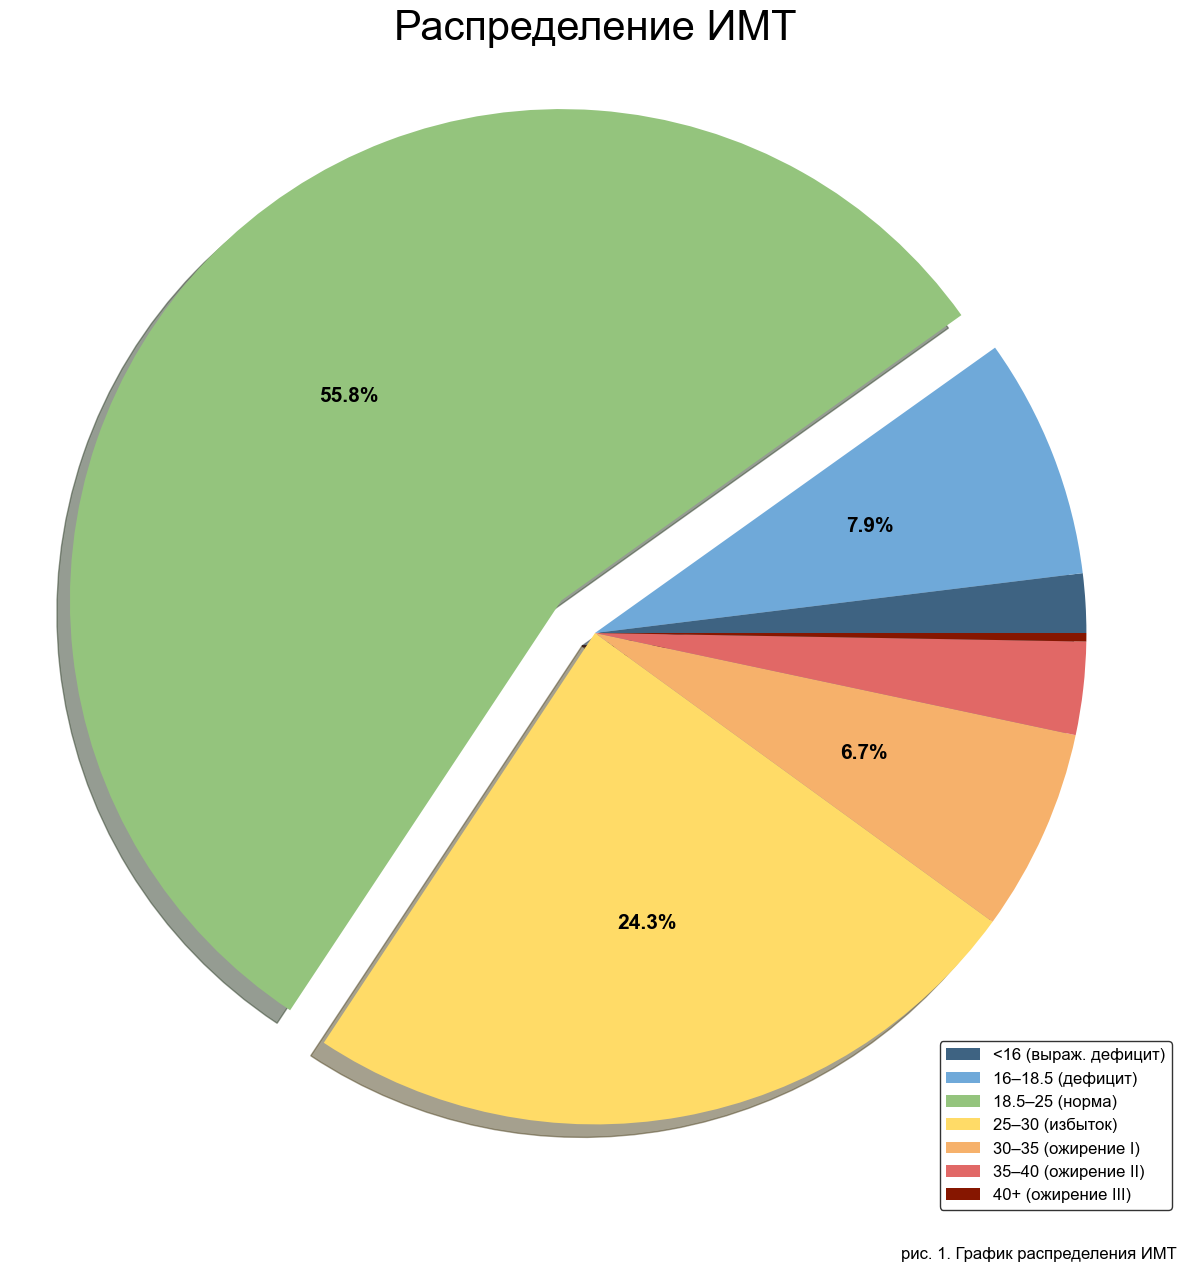

In [7]:
df_01['age_group'] = pd.cut(
    df_01.age, 
    bins=[18, 22, 26, 30, 35], 
    include_lowest=True, 
    labels=['18-22', '23-26', '27-30', '31-35']
)

df_01['bmi_group'] = pd.cut(
    df_01.bmi, 
    bins=[11, 16, 18.5, 25, 30, 35, 40, 65],
    include_lowest=True, 
    labels=['11-16', '16.1-18.5', '18.6-24.9', '25-29.9', '30-34.9', '35-39.9', '40+']
)

pt_bmi = df_01.pivot_table(
    index=['age_group', 'bmi_group'], 
    columns=['sex'], 
    values='participant_id',
    aggfunc='nunique'
).fillna(0).astype(int)

pt_bmi.columns.name = None 
display(pt_bmi.style.background_gradient(cmap='Blues'))

dangerous_bmi_low = df_01.loc[df_01.bmi <= 16]
dangerous_bmi_high = df_01.loc[df_01.bmi >= 30]
print(f'Количество людей со слишком низким ИМТ (<=16): {dangerous_bmi_low.shape[0]}')
print(f'Количество людей со слишком высоким ИМТ (>=30): {dangerous_bmi_high.shape[1]}')


plt.rcParams['font.family'] = 'Arial'
fig, ax = plt.subplots(figsize=(12, 17))
pt_bmi_pie = pt_bmi.droplevel(0).groupby(level=0).sum().sum(axis=1)


_, texts, _ = ax.pie(
    x=pt_bmi_pie.values, labels=['<16 (выраж. дефицит)', '16–18.5 (дефицит)', '18.5–25 (норма)', '25–30 (избыток)', '30–35 (ожирение I)', '35–40 (ожирение II)', '40+ (ожирение III)'], 
    colors=["#3E6382", '#6FA9D9', '#94C47D', '#FFDB67', '#F6B16B', '#E16866', "#861600"], 
    autopct=utils.autopct, 
    shadow=True, explode=(0, 0, .1, 0, 0, 0, 0), radius=1.05, 
    textprops={'size': 15, 'weight': 'bold'}
)
for t in texts: 
    t.set_visible(False)

ax.legend(**cn.LEGEND_PARAMS, loc='lower right')
ax.set_title('Распределение ИМТ', fontsize=30)

plt.suptitle('рис. 1. График распределения ИМТ', x=.87, y=.13)
plt.tight_layout()

#### 01.3. Расчет показателей активности и состояния в зависимости от ИМТ 

,low_bmi,high_bmi,normal_bmi
steps,6999.01,7015.80,8691.97
exercise_minutes,15.75,26.41,32.02
calories_kcal,1959.00,2835.75,2587.32
sleep_hours,6.10,6.48,7.02


,low_bmi,high_bmi,normal_bmi
stress_1_10,7.32,5.93,4.80
mood_1_10,4.24,5.07,6.71
energy_1_10,2.62,4.34,6.28
focus_1_10,4.02,5.04,6.45
mental_strain_0_10,7.09,5.64,3.53
productivity_score_0_100,49.64,57.90,71.50


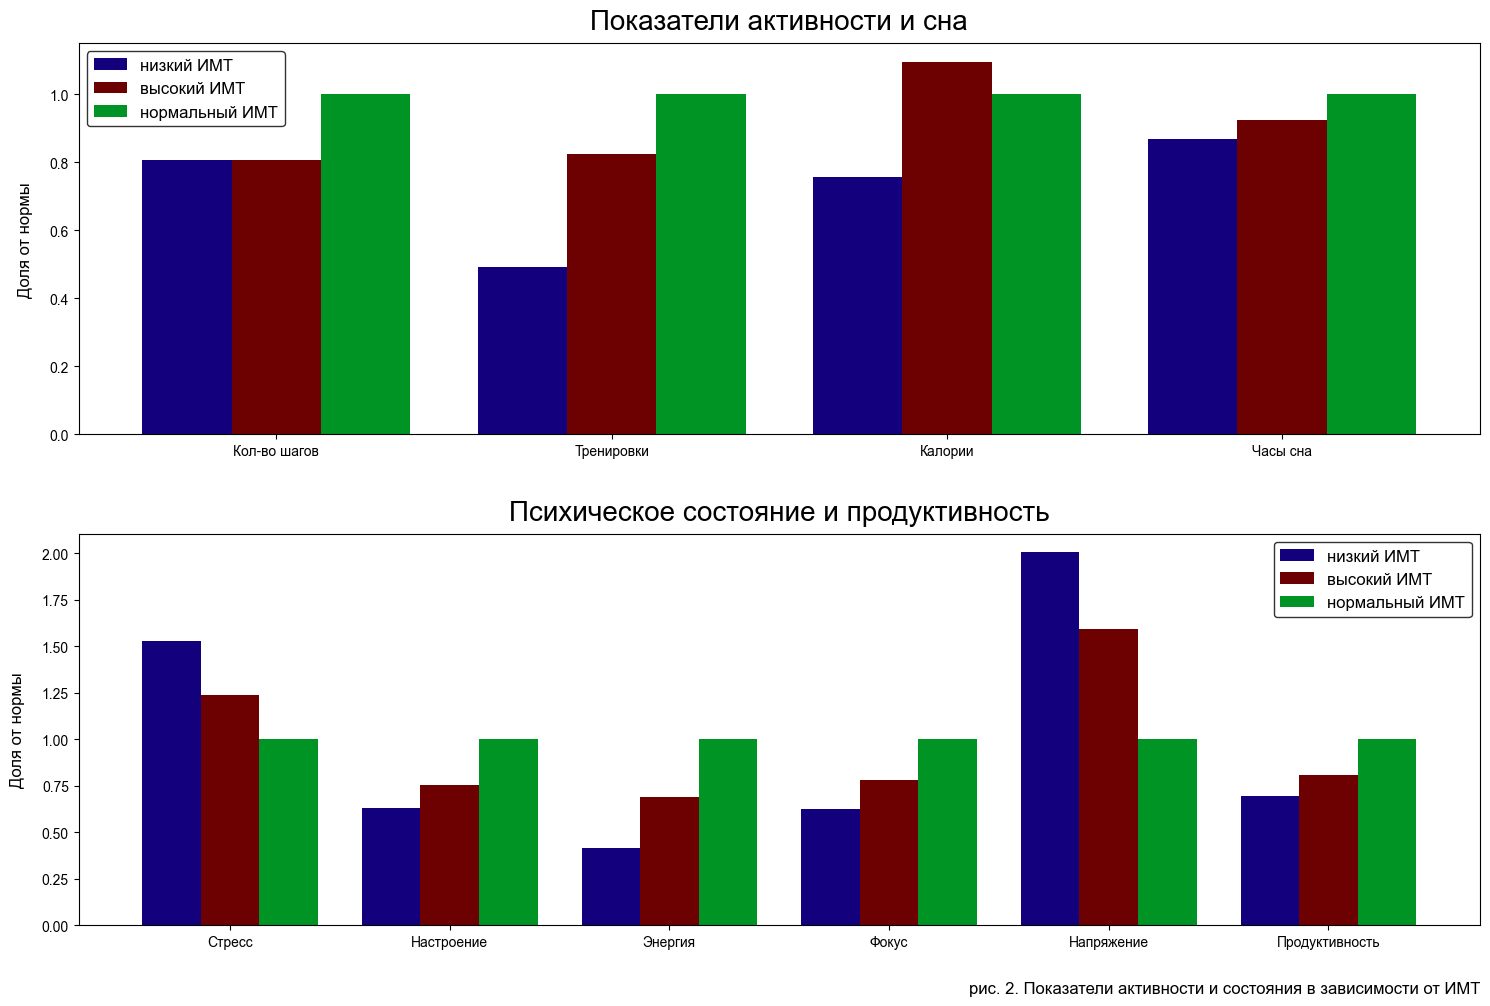

In [8]:
reasons = dict.fromkeys(r := ['steps', 'exercise_minutes', 'calories_kcal', 'sleep_hours'], 'mean')
consequences = dict.fromkeys(c := ['stress_1_10', 'mood_1_10', 'energy_1_10', 'focus_1_10', 'mental_strain_0_10', 'productivity_score_0_100'], 'mean')

mean_values_other_r = df_01.loc[(df_01.bmi > 16) & (df_01.bmi < 30)].agg(reasons)
mean_values_other_c = df_01.loc[(df_01.bmi > 16) & (df_01.bmi < 30)].agg(consequences)

stat_low_1 = dangerous_bmi_low.agg(reasons).to_frame().rename(columns={0: 'low_bmi'})
stat_high_1 = dangerous_bmi_high.agg(reasons).to_frame().rename(columns={0: 'high_bmi'})
stat_1 = stat_low_1.join([stat_high_1, mean_values_other_r.to_frame().rename(columns={0: 'normal_bmi'})])
display(stat_1.round(2))

stat_low_2 = dangerous_bmi_low.agg(consequences).to_frame().rename(columns={0: 'low_bmi'})
stat_high_2 = dangerous_bmi_high.agg(consequences).to_frame().rename(columns={0: 'high_bmi'})
stat_2 = stat_low_2.join([stat_high_2, mean_values_other_c.to_frame().rename(columns={0: 'normal_bmi'})])
display(stat_2.round(2))


fig, (ax1, ax2) = plt.subplots(2, figsize=(15, 10))
        
utils.normalize_and_draw_bar(stat_1, ax1)
utils.normalize_and_draw_bar(stat_2, ax2)

ax1.set_xticklabels(['Кол-во шагов', 'Тренировки', 'Калории', 'Часы сна'])
ax2.set_xticklabels(['Стресс', 'Настроение', 'Энергия', 'Фокус', 'Напряжение', 'Продуктивность'])

ax1.set_title('Показатели активности и сна', fontsize=20, pad=10)
ax2.set_title('Психическое состояние и продуктивность', fontsize=20, pad=10)

plt.suptitle('рис. 2. Показатели активности и состояния в зависимости от ИМТ', x=.82, y=-.017)
plt.tight_layout(h_pad=3)

#### 01.4. Выводы 

**Доля людей с разным ИМТ.** На основе проведенных расчетов и построенного графика (рис. 1) было выявлено, что большинство людей (55.8%) имеют здоровый индекс массы тела — от 18.5 до 25. Однако, 24.3% людей имеют избыточную массу тела (ИМТ в пределах 25.1-30), что само по себе не является опасным и не классифицируется как ожирение, но может доставлять неудобства в повседневной жизни. Также стоит заметить, что присутствуют люди, чей ИМТ в дефиците или классифицируется как ожирение I степени (7.9% и 6.7% соответственно), что уже представляет серьезную угрозу для здоровья. Остальные группы малочисленны, но их присутствие указывает на необходимость более пристального внимания к образу жизни групп риска.

**Причины и последствия низкого и высокого ИМТ (рис. 2).**   
Были найдены люди, чей ИМТ <=16 (576 чел.) и чей ИМТ >=30 (39 чел.). На основании проведенных расчетов показателей людей из данных групп можно сделать вывод, что главный фактор критически низкого / высокого индекса массы тела — калорийность, на которую питаются эти люди. Так, люди с критически низким ИМТ в среднем потребляют 1959 калорий, с критически высоким — 2836. При этом люди с нормальным ИМТ потребляют в среднем 2587 ккал в день, что является количеством, максимально приближенным к общепринятой норме. Количество шагов, время физических упражнений и часы сна не сильно разнятся у трех групп, однако шаги и тренировки у группы с низким ИМТ лишь усугубляют ситуацию (организм тратит энергию на физ. активность), а у группы с высоким — не компенсируют избыточное потребление калорий.   
При рассмотрении последствий наличия у людей слишком низкого и высокого ИМТ была найдена ожидаемая, но важная закономерность: уровень стресса и психического напряжения у людей чей ИМТ не находится в пределах нормы выше, а уровень настроения, энергии, фокусировки и продуктивности — ниже. 